In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


#Some code to beautify the plots
plt.rcParams['figure.figsize'] = [10, 5]
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14


These examples were taken from Carl Meyer's book "Matrix Analysis and Applied Linear Algebra"

## Quadratic curve fitting

A missile is fired from enemy territory and its position in flight is observed by radar tracking devices at the following positions


|Position (miles) | 0 | 250 | 500 | 750 | 1000 | 
|:---------------:|:-:|:---:|:---:|:---:|:----:|
| Height (miles)  | 0 | 8   | 15  |  19 | 20   |


**Problem**: Predict how far down the missile will land

First, we plot this data to see what we're dealing with. 

Text(0, 0.5, 'Height (miles))')

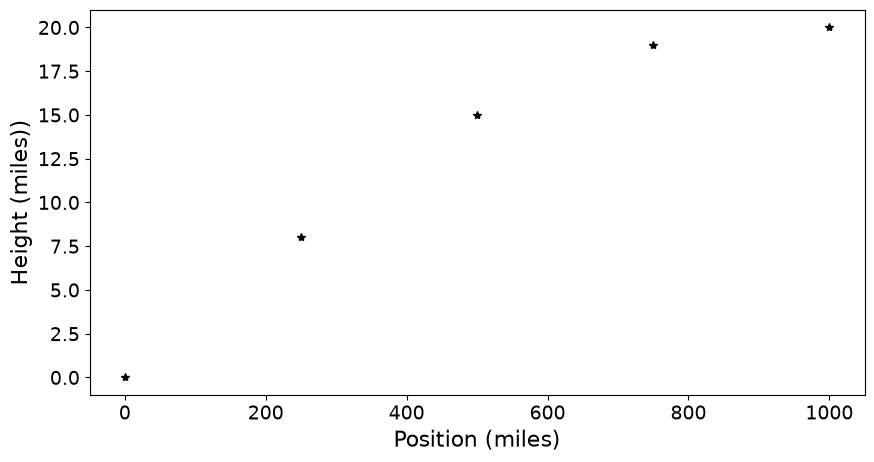

In [2]:
t = np.array([0.,250.,500.,750.,1000.])
b = np.array([0.,8.,15.,19.,20.])

plt.plot(t,b,'k*')
plt.xlabel('Position (miles)', fontsize = 16)
plt.ylabel('Height (miles))', fontsize = 16)

We can try to fit a quadratic function through this data. 

In [3]:
# Setup and solve least squares 

#Setup the matrix
t = t.reshape(5,1)
A = np.hstack((np.ones((5,1)),t,t**2.))


#Setup right hand side
b = b.reshape(5,1)

# Solve the least squares problem
x,_,_,_ = np.linalg.lstsq(A,b, rcond=None)

In [4]:
print('The coefficients of the least squares problem are \n')
print(x)

The coefficients of the least squares problem are 

[[-2.28571429e-01]
 [ 3.98285714e-02]
 [-1.94285714e-05]]


### Compute and plot the trajectory of the missile

Text(0, 0.5, 'Height (miles))')

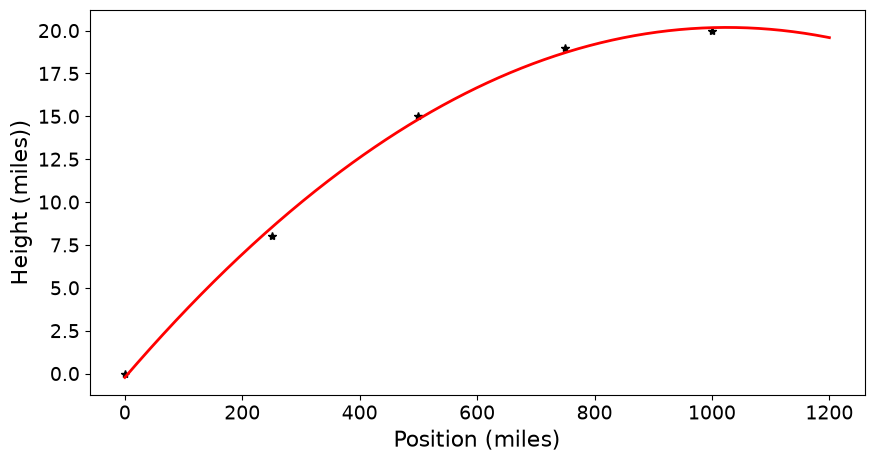

In [5]:
tp = np.linspace(0,1200,500)
p  = np.poly1d(x.flatten()[::-1])    # Construct a polynomial using the coefficients obtained using least squares
bp = p(tp)


plt.plot(t,b,'k*')
plt.plot(tp,bp,'r-', linewidth = 2.0)
plt.xlabel('Position (miles)', fontsize = 16)
plt.ylabel('Height (miles))', fontsize = 16)

To find where the missile lands, we have to "extrapolate" or predict using the quadratic model.

Text(0, 0.5, 'Height (miles)')

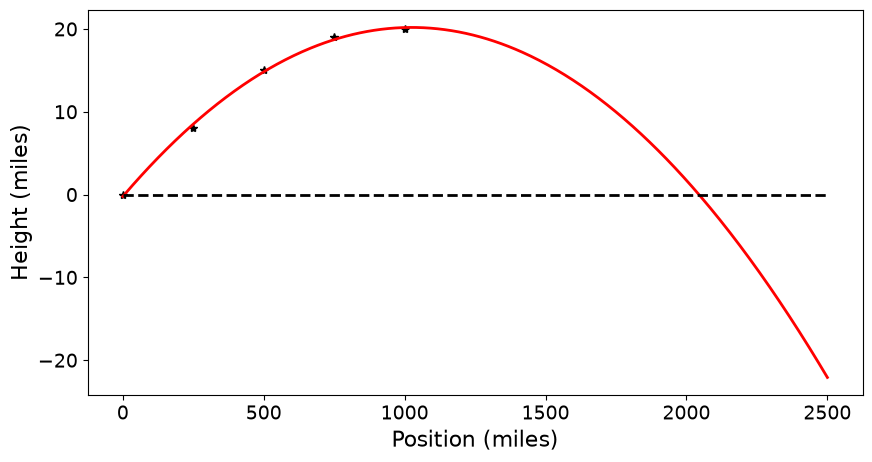

In [6]:
tp = np.linspace(0,2500,500)
p  = np.poly1d(x.flatten()[::-1])    # Construct a polynomial using the coefficients obtained using least squares
bp = p(tp)


plt.plot(t,b,'k*')
plt.plot(tp,bp,'r-', linewidth = 2.0)
plt.plot(tp,np.zeros((500,)), 'k--', linewidth = 2.0)
plt.xlabel('Position (miles)', fontsize = 16)
plt.ylabel('Height (miles)', fontsize = 16)

We can also find the zero crossing using a root finding function.

In [7]:
print('The roots of this quadratic, where the missile crosses the earth are ',p.roots)

The roots of this quadratic, where the missile crosses the earth are  [2044.24496276    5.75503724]


## Linear Regression

NC State's Howling Cow Ice Cream has a crisis. They seem to be losing icecream during the storage process. After some investigation, they discover that it is because of several factors (temperature, humidity, atmospheric pressure, butterfat content, etc.) But they believe storage time and temperatures are the primary factors and consider a linear regression model of the form 

$$ L = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + r $$

where $L$ = weight loss (grams), $x_1$ = storage time (weeks), $x_2$ = storage temperature (Fahrenheit), and $\epsilon$ is a random term that accounts for other factors.


They conduct several experiments on a pint of icecream and observe the following data

| Time (weeks) | 1 | 1 | 1 | 2 | 2 | 2 | 3 | 3 | 3 |
|:------------:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| Temp (F)     |-10|-5| 0 | -10| -5|0 | -10|-5| 0|
| Loss (grams) | 0.15|0.18|0.20|0.17|0.19|0.22|0.20|0.23|0.25|                                    
                            
We can estimate the coefficients $\beta_0,\beta_1,\beta_2$ using least squares. Once they have solved for these coefficients, they can use this model to plan their inventory. 

In [8]:
x1 = np.array([1.,1.,1.,2.,2.,2.,3.,3.,3.]).reshape(9,1)
x2 = np.array([-10.,-5.,0.,-10,-5.,0,-10,-5.,0.]).reshape(9,1)


X = np.hstack((np.ones((9,1)),x1,x2))
y = np.array([0.15,0.18,0.20,0.17,0.19,0.22,0.20,0.23,0.25])

beta,_,_,_ = np.linalg.lstsq(X,y, rcond = None)

In [9]:
print('The design matrix is')
print(X)
    
print('The data vector is')
print(y.reshape(9,1))

The design matrix is
[[  1.   1. -10.]
 [  1.   1.  -5.]
 [  1.   1.   0.]
 [  1.   2. -10.]
 [  1.   2.  -5.]
 [  1.   2.   0.]
 [  1.   3. -10.]
 [  1.   3.  -5.]
 [  1.   3.   0.]]
The data vector is
[[0.15]
 [0.18]
 [0.2 ]
 [0.17]
 [0.19]
 [0.22]
 [0.2 ]
 [0.23]
 [0.25]]


In [10]:
print('The least squares coefficients are \n')
print(beta)

The least squares coefficients are 

[0.17388889 0.025      0.005     ]


The estimated loss (in grams) of a pint of ice cream that is stored for nine weeks at a temperature of -35F is estimated to be 

In [11]:
print('Loss = %g grams' %(beta[0]+beta[1]*9+beta[2]*(-35.)) )

Loss = 0.223889 grams
